<a href="https://colab.research.google.com/github/sirisha142007/Prompt-Engineering-AI-Productivity/blob/main/Project_03_%E2%80%93_Customer_Churn_Sales_Trend_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
rng = np.random.default_rng(42)

n = 2000

orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") +
                  pd.to_timedelta(rng.integers(0, 365, n), unit="D"),

    "customer_id": rng.integers(1, 301, n),

    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.3, 0.35, 0.2, 0.15]
    ),

    "amount": rng.gamma(2.0, 600, n).round(2)
})

orders.head()

,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


In [3]:
print("Dataset Shape:")
print(orders.shape)

print("\nDataset Information:")
orders.info()

print("\nMissing Values:")
print(orders.isnull().sum())

print("\nDuplicate Records:")
print(orders.duplicated().sum())

print("\nStatistical Summary:")
display(orders.describe())

Dataset Shape:
(2000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[ns]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   object        
 3   amount       2000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 62.6+ KB

Missing Values:
order_date     0
customer_id    0
category       0
amount         0
dtype: int64

Duplicate Records:
0

Statistical Summary:


,order_date,customer_id,amount
count,2000,2000.000000,2000.000000
mean,2025-07-01 22:45:07.200000,151.195500,1202.116645
min,2025-01-01 00:00:00,1.000000,8.810000
25%,2025-03-31 18:00:00,74.000000,597.515000
50%,2025-07-02 00:00:00,149.000000,1005.870000
75%,2025-10-03 00:00:00,226.000000,1613.855000
max,2025-12-31 00:00:00,300.000000,6276.090000
std,NaN,86.210007,826.961568


In [4]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

orders["month"] = orders["order_date"].dt.to_period("M")

orders["weekday"] = orders["order_date"].dt.day_name()

orders["quarter"] = orders["order_date"].dt.quarter

orders["year"] = orders["order_date"].dt.year

display(orders.head())

,order_date,customer_id,category,amount,month,weekday,quarter,year
0,2025-02-02,264,Home,391.13,2025-02,Sunday,1,2025
1,2025-10-10,19,Fashion,2456.21,2025-10,Friday,4,2025
2,2025-08-27,120,Books,674.90,2025-08,Wednesday,3,2025
3,2025-06-10,138,Home,75.38,2025-06,Tuesday,2,2025
4,2025-06-08,240,Electronics,774.42,2025-06,Sunday,2,2025


In [5]:
monthly = orders.groupby("month")["amount"].sum()

print("Monthly Revenue:")
print(monthly.round(2))

monthly_growth = monthly.pct_change() * 100

print("\nMonth-over-Month Growth:")
print(monthly_growth.round(2))

print("\nBest Month:", monthly.idxmax())
print("Worst Month:", monthly.idxmin())

Monthly Revenue:
month
2025-01    193341.87
2025-02    232027.20
2025-03    206327.14
2025-04    197310.20
2025-05    194090.49
2025-06    221889.83
2025-07    221813.81
2025-08    179783.75
2025-09    180569.95
2025-10    183418.13
2025-11    191512.71
2025-12    202148.21
Freq: M, Name: amount, dtype: float64

Month-over-Month Growth:
month
2025-01      NaN
2025-02    20.01
2025-03   -11.08
2025-04    -4.37
2025-05    -1.63
2025-06    14.32
2025-07    -0.03
2025-08   -18.95
2025-09     0.44
2025-10     1.58
2025-11     4.41
2025-12     5.55
Freq: M, Name: amount, dtype: float64

Best Month: 2025-02
Worst Month: 2025-08


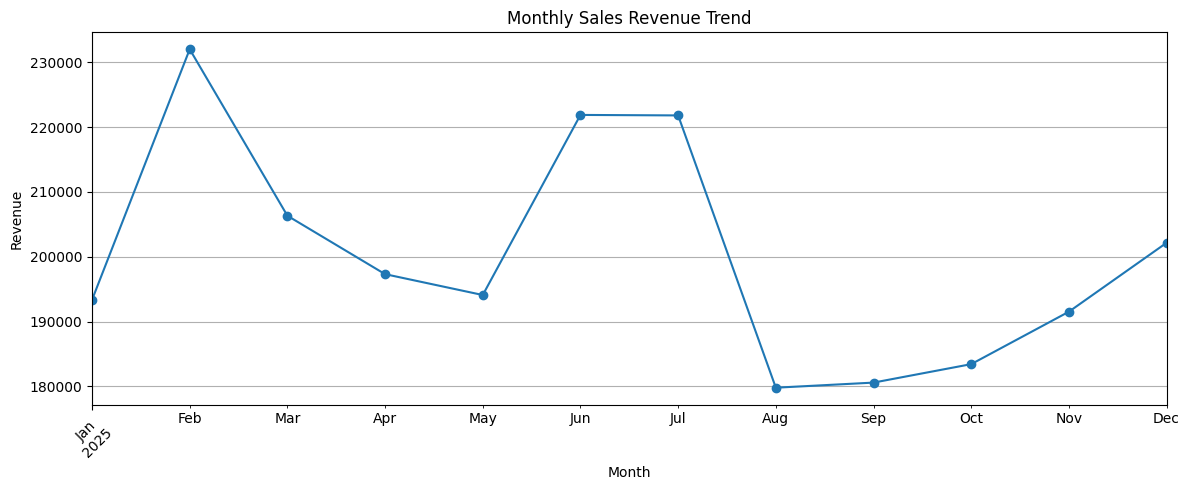

In [6]:
plt.figure(figsize=(12, 5))

monthly.plot(kind="line", marker="o")

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
by_category = orders.groupby("category")["amount"].agg(
    ["sum", "mean", "count"]
).sort_values("sum", ascending=False)

print("Category-wise Sales Analysis:")
display(by_category.round(2))

print("Best Performing Category:",
      by_category["sum"].idxmax())

Category-wise Sales Analysis:


,sum,mean,count
category,,,
Fashion,853984.93,1219.98,700
Electronics,722645.53,1163.68,621
Home,464114.66,1218.15,381
Books,363488.17,1219.76,298


Best Performing Category: Fashion


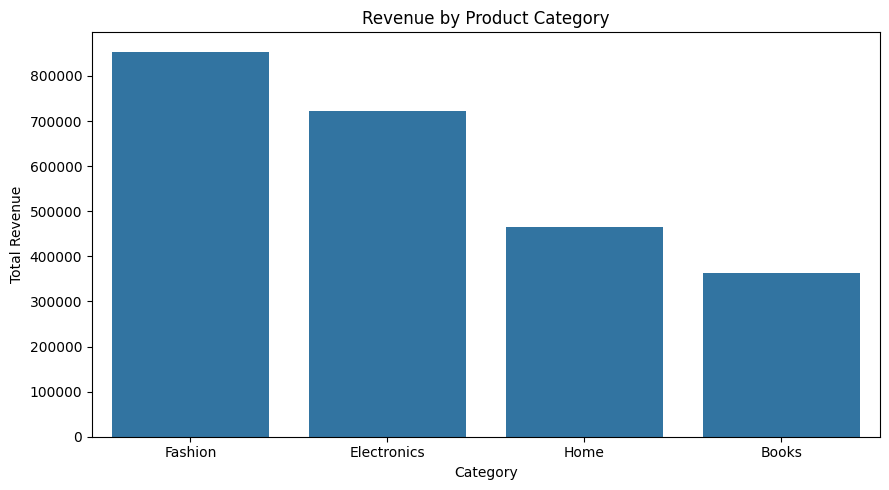

In [8]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=by_category.index,
    y=by_category["sum"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

In [9]:
pivot_table = pd.pivot_table(
    orders,
    values="amount",
    index="month",
    columns="category",
    aggfunc="sum",
    fill_value=0
)

print("Monthly Revenue by Category:")
display(pivot_table.round(2))

Monthly Revenue by Category:


category,Books,Electronics,Fashion,Home
month,,,,
2025-01,29186.89,62841.89,64665.99,36647.10
2025-02,34034.13,53564.89,86123.31,58304.87
2025-03,27843.58,58055.95,75138.67,45288.94
2025-04,26593.72,83335.56,57057.72,30323.20
2025-05,34425.63,57219.16,68569.90,33875.80
2025-06,32936.76,60037.00,85598.09,43317.98
2025-07,35582.36,72649.65,72647.96,40933.84
2025-08,32550.65,56690.46,71251.54,19291.10
2025-09,21824.73,60388.56,60231.75,38124.91


In [10]:
spend = orders.groupby("customer_id")["amount"].sum()

spend = spend.sort_values(ascending=False)

print("Top 10 Customers:")
display(spend.head(10).to_frame("Total Spending"))

top_10_percent = spend.head(
    max(1, int(np.ceil(len(spend) * 0.10)))
)

top_share = top_10_percent.sum() / spend.sum()

print(f"\nTop 10% of customers contribute {top_share:.2%} of total revenue.")

Top 10 Customers:


,Total Spending
customer_id,
226,18140.15
51,18126.28
53,17994.36
131,17639.25
185,17222.49
282,17161.00
121,16564.87
98,15351.48
255,15313.47



Top 10% of customers contribute 18.94% of total revenue.


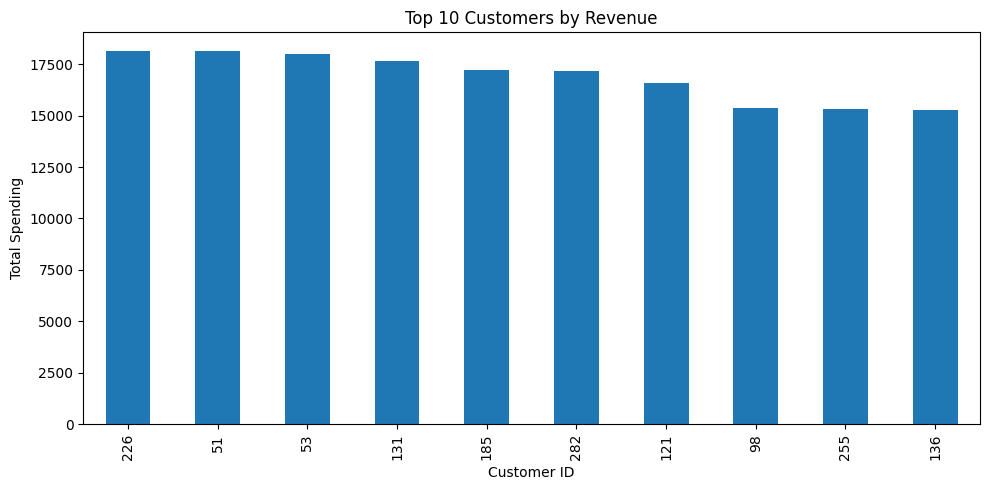

In [11]:
plt.figure(figsize=(10, 5))

spend.head(10).plot(kind="bar")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")

plt.tight_layout()
plt.show()

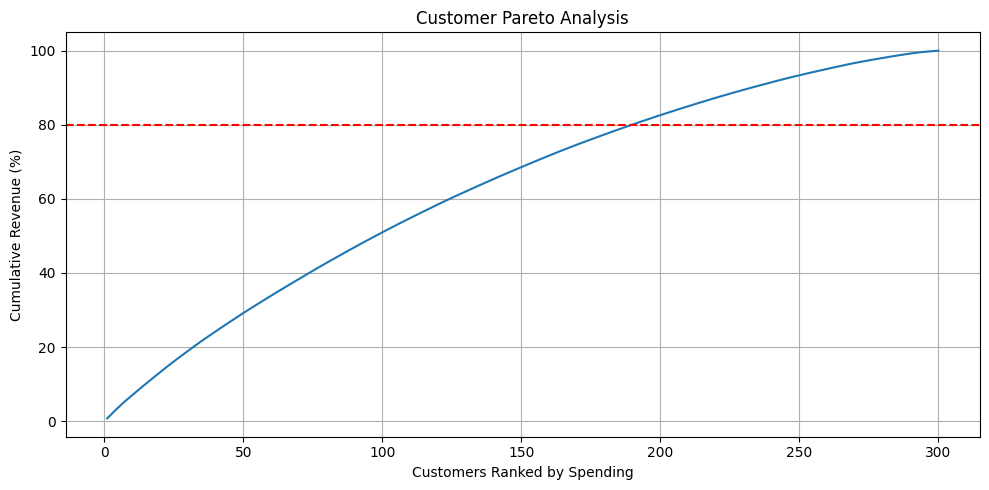

In [12]:
cumulative_revenue = spend.cumsum() / spend.sum()

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_revenue) + 1),
    cumulative_revenue * 100
)

plt.axhline(y=80, linestyle="--", color="red")

plt.title("Customer Pareto Analysis")
plt.xlabel("Customers Ranked by Spending")
plt.ylabel("Cumulative Revenue (%)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
best_category = by_category["sum"].idxmax()
best_month = monthly.idxmax()
worst_month = monthly.idxmin()

print("BUSINESS RECOMMENDATIONS")
print("--------------------------------")

print(f"1. Focus marketing campaigns on the {best_category} category because it generates the highest revenue.")

print(f"2. Introduce special promotions during weaker sales periods. The lowest revenue month is {worst_month}.")

print(f"3. Introduce loyalty rewards for the top 10% of customers, who contribute {top_share:.2%} of total revenue.")

print("\nAnalysis completed successfully!")

BUSINESS RECOMMENDATIONS
--------------------------------
1. Focus marketing campaigns on the Fashion category because it generates the highest revenue.
2. Introduce special promotions during weaker sales periods. The lowest revenue month is 2025-08.
3. Introduce loyalty rewards for the top 10% of customers, who contribute 18.94% of total revenue.

Analysis completed successfully!


In [14]:
print("PROJECT 03: CUSTOMER CHURN / SALES TREND ANALYSIS")
print("=" * 55)

print("\n1. DATASET INFORMATION")
print("Total Orders:", len(orders))
print("Unique Customers:", orders["customer_id"].nunique())
print("Total Revenue: ₹", round(orders["amount"].sum(), 2))

print("\n2. SALES TREND")
print("Best Month:", best_month)
print("Worst Month:", worst_month)

print("\n3. CATEGORY PERFORMANCE")
print("Top Category:", best_category)

print("\n4. CUSTOMER ANALYSIS")
print(f"Revenue from Top 10% Customers: {top_share:.2%}")

print("\n5. CONCLUSION")
print("The analysis identifies monthly revenue trends,")
print("best-performing categories and valuable customers.")
print("The findings can help improve business decisions.")

PROJECT 03: CUSTOMER CHURN / SALES TREND ANALYSIS

1. DATASET INFORMATION
Total Orders: 2000
Unique Customers: 300
Total Revenue: ₹ 2404233.29

2. SALES TREND
Best Month: 2025-02
Worst Month: 2025-08

3. CATEGORY PERFORMANCE
Top Category: Fashion

4. CUSTOMER ANALYSIS
Revenue from Top 10% Customers: 18.94%

5. CONCLUSION
The analysis identifies monthly revenue trends,
best-performing categories and valuable customers.
The findings can help improve business decisions.
